# 25 — Time-varying currency risk prices across countries

First audit the conditioning information, then allow **both national and other FX risk prices**
to vary for **Poland, Czechia, Romania, Sweden and Hungary**, in **USD and EUR**, under
**scalar and diagonal BEKK**. Every fit uses the same frozen **October 2014–September 2026,
144 months** and the existing **Python 3 (base)** kernel.

Keep notebook 24's time-varying world specification, corrected priced means in all five equations,
zero equity alphas, and constant US/national local prices. Re-estimate all free parameters jointly.
Compare 20 new systems against their 20 verified time-varying-world/constant-FX references.
No fetching, package installation, revised data or changes to earlier research outputs.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 2500
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_time_varying_currency_priced_means_v1"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
NATIONAL_INFLATION_FORM = "change"  # primary; optional separate configuration: "level"
OTHER_INFLATION_FORM = "level"      # primary; optional separate configuration: "change"
INCLUDE_REGIME = True
PREVIOUS_MANIFEST_SHA = "fba674a6acf74010e595856510091ac7570ed906a4db76db722fdce57af1eaf9"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_fx_price_variation as engine
importlib.reload(engine)

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output"/"24_regional_time_varying_world"/"2014-10_2026-09"/"z_c1170c40"
CANDIDATES = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
assert NATIONAL_INFLATION_FORM in ["change", "level"] and OTHER_INFLATION_FORM in ["change", "level"]
spec = {"world_instruments": WORLD_INSTRUMENTS, "national_inflation": NATIONAL_INFLATION_FORM,
        "other_inflation": OTHER_INFLATION_FORM, "include_varying_regime": INCLUDE_REGIME,
        "world_design_sha256": "b59be89293797cc8740eb29a35f81f742818a6d839222594f0162c2309f18acf"}
instrument_id = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:8]
OUT = ROOT/"output"/"25_regional_time_varying_currency"/"2014-10_2026-09"/f"fx_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_fx_price_variation.py", "regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import InterpolationWarning
print("Currency-price engine SHA-256:", engine_hashes["regional_fx_price_variation.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Currency-price engine SHA-256: 9a34a4b0199ec91cc43b10d912a38d9d16df5899a4fde047c29b6deba809f753


## 1. Verify the frozen common sample

Verify notebook 24's manifest, all inherited input/output hashes and engines, and the ten frozen
five-series datasets. Hungary is refitted on the same regional window. USD and EUR are two
numeraires of the same observations, not independent replications. FX returns are spot log changes:
a positive national FX return means appreciation against the investor currency.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-24 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 1149 protected files and all ten five-series input systems.


## 2. Audit timing, inflation forms, regimes and design rank before fitting

Retain the three lagged global financial predictors from notebook 24 in **each** price function.
Reconstruct them from frozen FRED. Reconstruct annual US CPI and European HICP inflation from
raw levels on the full pre-sample calendar, then construct gaps and lags **before trimming**:

* National gap: investor inflation minus national inflation, lagged two months. Primary form:
  **change in that gap**. Its level is audited too.
* Other FX gap: US minus euro-area inflation for USD investors, the reverse for EUR investors,
  lagged two months. Primary form: **level**; its change is audited too.
* National FX alone also uses an existing regime indicator when it varies. In this window only
  Czechia's exchange-rate-floor indicator varies (December 2013–April 2017). Drop and record
  constant indicators: PL/HU are all one, RO/SE are zero placeholders, not fixed-rate classifications.

Preserve the inherited one-month carry of the **US annual inflation rate** for missing October
2025 CPI. Do not fill CPI levels or national HICP. This affects lagged levels in **December 2025**
and lagged differences in **December 2025 and January 2026**. Explicit flags remain in the audit.
US CPI and European HICP are imperfectly comparable concepts. Two-month lags approximate
availability; historical downloads are not real-time vintages.

Check both inflation forms, persistence, ADF/KPSS, missingness, regime support, normalization,
rank, VIF, conditioning and leverage. No significance-based instrument selection, data deletion or
winsorisation. Gap levels can remain persistent even when a design has full rank. The defaults
follow the earlier Hungarian specification; alternative forms create separate output folders.
Keep notebook 24's world design byte-identical. Center/scale added columns on these 144 months
(sample SD, ddof=1); this is an in-sample reparameterisation, not out-of-sample prediction.

lag1_correlation  ADF_p_raw KPSS_p_report
country perspective instrument                                                
HU      USD         national_change            0.7581     0.0042         >=0.1
                    other_level                0.9430     0.0873         >=0.1
        EUR         national_change            0.5619     0.0008         >=0.1
                    other_level                0.9430     0.0873         >=0.1
PL      USD         national_change            0.4913     0.0000         >=0.1
                    other_level                0.9430     0.0873         >=0.1
        EUR         national_change            0.2775     0.0031         >=0.1
                    other_level                0.9430     0.0873         >=0.1
CZ      USD         national_change            0.1929     0.0002         >=0.1
                    other_level                0.9430     0.0873         >=0.1
        EUR         national_change            0.0389     0.0084         >=0.1
                    other_level                0.9430     0.0873         >=0.1
RO      USD         national_change            0.2306     0.0032         >=0.1
                    other_level                0.9430     0.0873         >=0.1
        EUR         national_change            0.0366     0.0000         >=0.1
                    other_level                0.9430     0.0873         >=0.1
SE      USD         national_change            0.0764     0.0000         >=0.1
                    other_level                0.9430     0.0873         >=0.1
        EUR         national_change           -0.1906     0.0000         >=0.1
                    other_level                0.9430     0.0873         >=0.1

rank  columns  condition_number  max_leverage
country perspective factor                                               
HU      USD         W          4        4            1.7991        0.4065
                    H          5        5            1.9625        0.4498
                    O          5        5            2.0729        0.4080
        EUR         W          4        4            1.7991        0.4065
                    H          5        5            1.9156        0.4314
                    O          5        5            2.0729        0.4080
PL      USD         W          4        4            1.7991        0.4065
                    H          5        5            1.8622        0.4285
                    O          5        5            2.0729        0.4080
        EUR         W          4        4            1.7991        0.4065
                    H          5        5            1.8837        0.4121
                    O          5        5            2.0729        0.4080
CZ      USD         W          4        4            1.7991        0.4065
                    H          6        6            1.8464        0.4243
                    O          5        5            2.0729        0.4080
        EUR         W          4        4            1.7991        0.4065
                    H          6        6            1.8300        0.4191
                    O          5        5            2.0729        0.4080
RO      USD         W          4        4            1.7991        0.4065
                    H          5        5            1.8366        0.4066
                    O          5        5            2.0729        0.4080
        EUR         W          4        4            1.7991        0.4065
                    H          5        5            1.8022        0.4151
                    O          5        5            2.0729        0.4080
SE      USD         W          4        4            1.7991        0.4065
                    H          5        5            1.8709        0.4135
                    O          5        5            2.0729        0.4080
        EUR         W          4        4            1.7991        0.4065
                    H          5        5            1.8399        0.4065
                    O          5        5            2.0729        0.4080

ones  zeros   used                   reason first_one  \
country perspective                                                          
HU      USD           144      0  False       constant; excluded   2014-10   
        EUR           144      0  False       constant; excluded   2014-10   
PL      USD           144      0  False       constant; excluded   2014-10   
        EUR           144      0  False       constant; excluded   2014-10   
CZ      USD            31    113   True  varying floor indicator   2014-10   
        EUR            31    113   True  varying floor indicator   2014-10   
RO      USD             0    144  False       constant; excluded             
        EUR             0    144  False       constant; excluded             
SE      USD             0    144  False       constant; excluded             
        EUR             0    144  False       constant; excluded             

                    last_one  
country perspective           
HU      USD          2026-09  
        EUR          2026-09  
PL      USD          2026-09  
        EUR          2026-09  
CZ      USD          2017-04  
        EUR          2017-04  
RO      USD                   
        EUR                   
SE      USD                   
        EUR

flagged_months
country perspective                  
CZ      EUR                   2025-12
        USD          2025-12, 2026-01
HU      EUR                   2025-12
        USD          2025-12, 2026-01
PL      EUR                   2025-12
        USD          2025-12, 2026-01
RO      EUR                   2025-12
        USD          2025-12, 2026-01
SE      EUR                   2025-12
        USD          2025-12, 2026-01

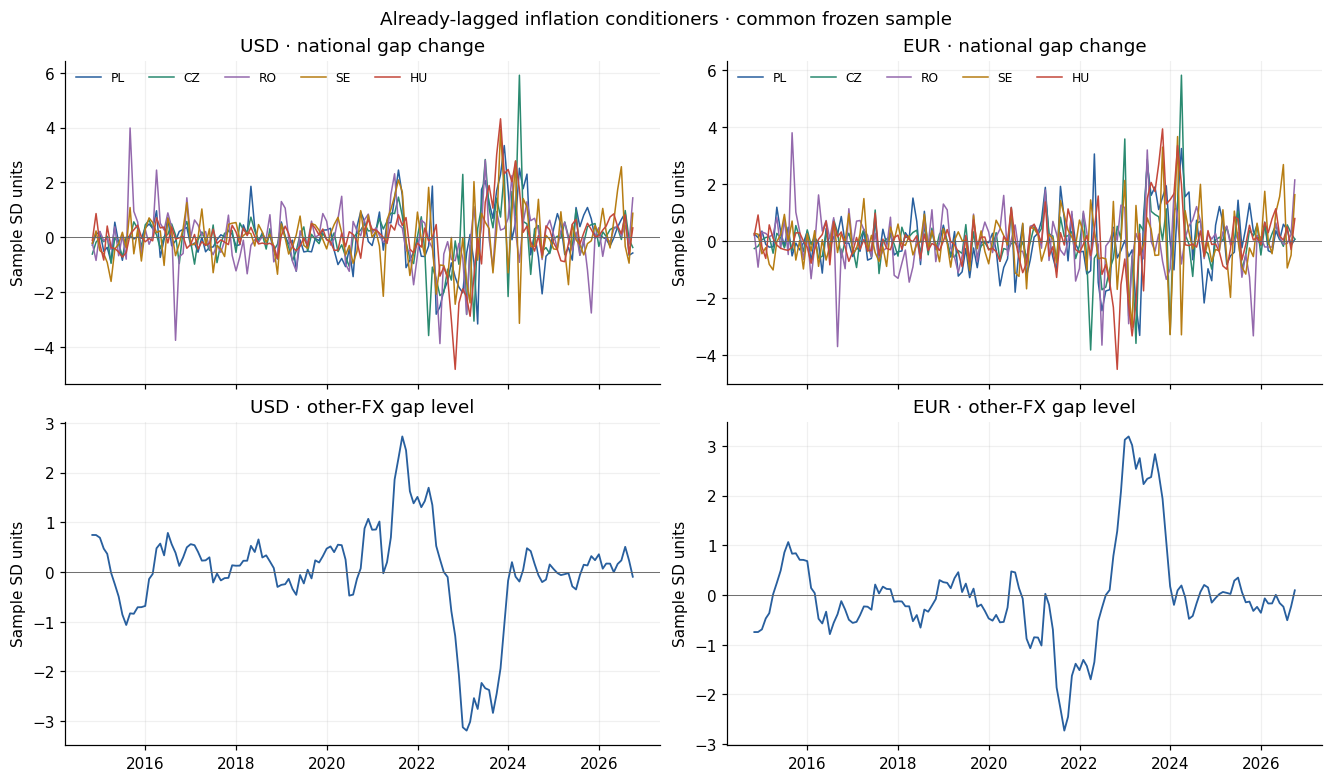

Audit passed: no missing predictors; full-rank designs; world normalization unchanged. Persistent other-FX levels and carried-US observations remain explicit concerns.


In [3]:
old = json.loads((PREVIOUS/"estimation_manifest.json").read_text())
assert old["world_instruments"] == WORLD_INSTRUMENTS
world_frame = pd.read_csv(PREVIOUS/"conditioning_design.csv", index_col=0, float_precision="round_trip")
Z = world_frame.to_numpy()
assert sha(Z.tobytes()) == spec["world_design_sha256"] == old["conditioning_sha256"]
assert list(world_frame.columns) == ["constant"]+WORLD_INSTRUMENTS
assert pd.PeriodIndex(world_frame.index, freq="M").equals(months)
fred = pd.read_csv(ROOT/locks["research_synthesis_inputs.json"]["snapshot"]/"raw/fred.csv", index_col=0, float_precision="round_trip")
fred.index = pd.PeriodIndex(fred.index, freq="M")
assert fred.index.is_unique
fred = fred.reindex(pd.period_range(fred.index.min(), fred.index.max(), freq="M"))
rebuilt_global = pd.DataFrame({CANDIDATES[0]: fred.TB3MS.diff().shift(1),
    CANDIDATES[1]: (fred.GS10-fred.TB3MS).diff().shift(1), CANDIDATES[2]: (fred.BAA-fred.AAA).shift(1)}).loc[months]
for d in frames.values(): np.testing.assert_allclose(d[CANDIDATES], rebuilt_global, atol=1e-12, rtol=0)
np.testing.assert_allclose(Z[:, 1:], (rebuilt_global.to_numpy()-np.array([old["centres"][n] for n in WORLD_INSTRUMENTS]))/
    np.array([old["spreads_ddof1"][n] for n in WORLD_INSTRUMENTS]), atol=1e-12, rtol=0)

def hicp(path):
    j = json.loads(path.read_text()); flat = np.full(np.prod(j["size"]), np.nan)
    assert j["id"] == ["freq", "unit", "coicop18", "geo", "time"] and j["size"][:3] == [1, 1, 1]
    for pos, value in j["value"].items(): flat[int(pos)] = value
    values = flat.reshape(j["size"])[0, 0, 0]
    geo = j["dimension"]["geo"]["category"]["index"]
    time = j["dimension"]["time"]["category"]["index"]
    return pd.DataFrame({g: values[i] for g, i in geo.items()}, index=pd.PeriodIndex(sorted(time, key=time.get), freq="M"))
calendar = pd.period_range("1998-01", "2026-09", freq="M")
original_root = ROOT/locks["research_synthesis_inputs.json"]["snapshot"]
levels = pd.concat([hicp(original_root/"raw/eurostat_hicp.json"), hicp(ROOT/regional["root"]/"raw/national_hicp.json")], axis=1).reindex(calendar)
annual = levels.pct_change(12, fill_method=None)*100
us_raw = fred.CPIAUCNS.reindex(calendar).pct_change(12, fill_method=None)*100
us = us_raw.ffill(limit=1)
carried = us_raw.isna() & us.notna()
assert list(carried[carried].index.astype(str)) == ["2025-10"]
raw_candidates, flags, audit_rows, regime_rows = {}, {}, [], []
for key, d in frames.items():
    country, currency = key
    investor = us if currency == "USD" else annual.EA
    national_gap = investor-annual[country]
    other_gap = us-annual.EA if currency == "USD" else annual.EA-us
    raw = pd.DataFrame({"national_level": national_gap.shift(2), "national_change": national_gap.diff().shift(2),
        "other_level": other_gap.shift(2), "other_change": other_gap.diff().shift(2)}).loc[months]
    assert np.isfinite(raw.to_numpy()).all()
    for a, b in [("national_level", "inflation_gap_lag2_pp"), ("national_change", "inflation_gap_change_lag2_pp"), ("other_level", "other_fx_gap_lag2_pp")]:
        np.testing.assert_allclose(raw[a], d[b], atol=1e-12, rtol=0)
    level_flag = carried.shift(2, fill_value=False).loc[months]
    change_flag = (carried | carried.shift(1, fill_value=False)).shift(2, fill_value=False).loc[months]
    np.testing.assert_array_equal(level_flag, d.flag_us_inflation_carried_lag2.astype(bool))
    flags[key] = pd.DataFrame({"national_uses_carried_US": (change_flag if NATIONAL_INFLATION_FORM == "change" else level_flag) & (currency == "USD"),
        "other_uses_carried_US": change_flag if OTHER_INFLATION_FORM == "change" else level_flag}, index=months)
    regime = d.regime_indicator
    expected_regime = ((months >= "2013-12") & (months <= "2017-04")).astype(float) if country == "CZ" else np.full(len(months), float(country in ["HU", "PL"]))
    np.testing.assert_array_equal(regime, expected_regime)
    varying = regime.nunique() > 1
    regime_rows.append({"country": country, "perspective": currency, "ones": int(regime.sum()), "zeros": int((regime == 0).sum()),
        "used": bool(INCLUDE_REGIME and varying), "reason": "varying floor indicator" if varying else "constant; excluded",
        "first_one": str(months[regime.to_numpy() == 1][0]) if regime.sum() else "", "last_one": str(months[regime.to_numpy() == 1][-1]) if regime.sum() else ""})
    raw_candidates[key] = raw
    for name in raw:
        v = raw[name]; a = adfuller(v, maxlag=12, regression="c", autolag="AIC", result_object=False)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", InterpolationWarning)
            k = kpss(v, regression="c", nlags="auto", result_object=False)
        bound = (">=" if k[1] >= .1 else "<=") if any(issubclass(w.category, InterpolationWarning) for w in caught) else ""
        audit_rows.append({"country": country, "perspective": currency, "instrument": name,
            "used": name in ["national_"+NATIONAL_INFLATION_FORM, "other_"+OTHER_INFLATION_FORM], "n": len(v), "missing": int(v.isna().sum()),
            "mean_pp": v.mean(), "sd_pp": v.std(ddof=1), "lag1_correlation": v.autocorr(), "ADF_stat": a[0], "ADF_p_raw": a[1],
            "ADF_lags": a[2], "KPSS_stat": k[0], "KPSS_p_report": f"{bound}{k[1]:.5g}", "KPSS_lags": k[2]})
audit, regimes = pd.DataFrame(audit_rows), pd.DataFrame(regime_rows)
designs, design_names, transforms, design_rows, vif_rows, leverage_rows, conditioning_rows, flag_rows, candidate_rows = {}, {}, [], [], [], [], [], [], []
for key, d in frames.items():
    country, currency = key; raw = raw_candidates[key]
    designs[key], design_names[key] = {"W": Z}, {"W": ["constant"]+WORLD_INSTRUMENTS}
    for factor, extra_name in [("H", "national_"+NATIONAL_INFLATION_FORM), ("O", "other_"+OTHER_INFLATION_FORM)]:
        extras = raw[[extra_name]].copy()
        if factor == "H" and INCLUDE_REGIME and d.regime_indicator.nunique() > 1: extras["regime_indicator"] = d.regime_indicator
        center, spread = extras.mean(), extras.std(ddof=1)
        assert spread.gt(0).all()
        designs[key][factor] = np.c_[Z, ((extras-center)/spread).to_numpy()]
        design_names[key][factor] = ["constant"]+WORLD_INSTRUMENTS+list(extras)
        transforms.extend({"country": country, "perspective": currency, "factor": factor, "instrument": n, "mean": center[n], "sd_ddof1": spread[n]} for n in extras)
    for factor, D in designs[key].items():
        assert np.isfinite(D).all() and np.linalg.matrix_rank(D) == D.shape[1]
        np.testing.assert_allclose(D[:, 1:].mean(axis=0), 0, atol=1e-14, rtol=0)
        leverage = np.sum(np.linalg.qr(D, mode="reduced")[0]**2, axis=1)
        design_rows.append({"country": country, "perspective": currency, "factor": factor, "rank": np.linalg.matrix_rank(D), "columns": D.shape[1],
            "condition_number": np.linalg.cond(D), "max_leverage": leverage.max(), "max_leverage_month": str(months[leverage.argmax()]),
            "high_leverage_months": int((leverage > 2*D.shape[1]/len(months)).sum()), "design_sha256": sha(D.tobytes())})
        vif_rows.extend({"country": country, "perspective": currency, "factor": factor, "instrument": n,
            "VIF": variance_inflation_factor(D, j)} for j, n in enumerate(design_names[key][factor]) if j)
        leverage_rows.extend({"country": country, "perspective": currency, "factor": factor, "month": str(m), "leverage": leverage[t],
            "reference_2p_over_n": 2*D.shape[1]/len(months)} for t, m in enumerate(months))
        conditioning_rows.extend({"country": country, "perspective": currency, "factor": factor, "month": str(m),
            "instrument": n, "value": D[t, j]} for j, n in enumerate(design_names[key][factor]) for t, m in enumerate(months))
    flag_rows.extend({"country": country, "perspective": currency, "month": str(m), **flags[key].iloc[t].to_dict()} for t, m in enumerate(months))
    candidate_rows.extend({"country": country, "perspective": currency, "month": str(m), **raw.iloc[t].to_dict()} for t, m in enumerate(months))
transform_table, design_audit, vifs, leverages, conditioning, quality_flags, candidates = map(pd.DataFrame,
    [transforms, design_rows, vif_rows, leverage_rows, conditioning_rows, flag_rows, candidate_rows])
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional currency-price notebook 25"})
    figure_files.append(name); plt.show(); plt.close()
display(audit.query("used").set_index(["country", "perspective", "instrument"])[["lag1_correlation", "ADF_p_raw", "KPSS_p_report"]].round(4))
display(design_audit.set_index(["country", "perspective", "factor"])[["rank", "columns", "condition_number", "max_leverage"]].round(4))
display(regimes.set_index(["country", "perspective"]))
display(quality_flags.query("national_uses_carried_US or other_uses_carried_US").groupby(["country", "perspective"])
    .agg(flagged_months=("month", lambda s: ", ".join(s))))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for col, currency in enumerate(CURRENCIES):
    for country in NAMES:
        D = designs[(country, currency)]["H"]
        axes[0, col].plot(months.to_timestamp("M"), D[:, 4], color=COLORS[country], lw=1, label=country)
    axes[0, col].set(title=f"{currency} · national gap {NATIONAL_INFLATION_FORM}", ylabel="Sample SD units")
    axes[0, col].legend(ncol=5, frameon=False, fontsize=8)
    axes[1, col].plot(months.to_timestamp("M"), designs[("HU", currency)]["O"][:, 4], color="#285f9e", lw=1.2)
    axes[1, col].set(title=f"{currency} · other-FX gap {OTHER_INFLATION_FORM}", ylabel="Sample SD units")
    for ax in axes[:, col]: ax.axhline(0, color="#666666", lw=.6)
fig.suptitle("Already-lagged inflation conditioners · common frozen sample")
save_plot("01_inflation_instruments.png")
print("Audit passed: no missing predictors; full-rank designs; world normalization unchanged. Persistent other-FX levels and carried-US observations remain explicit concerns.")

## 3. Add two conditional FX-price functions

$$\boxed{\lambda_{c,t}=b_{c,0}+\boldsymbol b_{c,G}'\widetilde{\boldsymbol G}_{t-1}
+b_{c,\pi}\widetilde{\Delta(\pi_{I}-\pi_c)}_{t-2}
+b_{c,D}\widetilde D_t,\qquad
\lambda_{o,t}=b_{o,0}+\boldsymbol b_{o,G}'\widetilde{\boldsymbol G}_{t-1}
+b_{o,\pi}\widetilde{(\pi_I-\pi_o)}_{t-2}.}$$

Here c is the national currency and o is EUR for USD investors, USD for EUR investors. D enters
only when its known regime indicator varies (Czechia in this window). Tildes denote the recorded
common-window normalization. The already-lagged stored columns receive **no extra lag**.
The world price remains linear in its same three global instruments. All three price functions
are unrestricted in sign. Intercepts equal their average fitted prices; slopes measure changes
per one sample SD. These are risk prices, in inverse percentage points, not equity premiums.

For each of the five series i, retain the corrected conditional mean:

$$E[y_{i,t}\mid\mathcal F_{t-1}]=\lambda_{W,t}H_{iW,t}+\lambda_{c,t}H_{ic,t}
+\lambda_{o,t}H_{io,t}+\mathbf 1_{i\in\{US,national\}}\lambda_iH_{ii,t}.$$

Both FX equations follow this same restriction. Local prices remain constant and there are no
alphas. The default adds **8 FX slopes**, or **9 for Czechia**: parameter counts 25→33 (scalar)
and 33→41 (diagonal), with one extra for Czechia. Both covariance recursions and stationary
innovation initialization stay unchanged. Setting only the added FX slopes to zero nests notebook 24.

In [4]:
constant_fits, check_rows = {}, []
for key, y in samples.items():
    country, currency = key; D, scale = designs[key], scales[key]
    for covariance in COVARIANCES:
        record = json.loads((PREVIOUS/f"fit_{country}_{currency}_{covariance}_time_varying.json").read_text())
        config = record["config"]
        assert (config["country"], config["perspective"], config["covariance"], config["source_sha256"]) == (country, currency, covariance, source_hashes[key])
        assert record["fingerprint"] == sha(json.dumps(config, sort_keys=True).encode()+y.tobytes()+Z.tobytes())
        theta0 = np.asarray(record["theta"])
        base = engine.filter_model(theta0, y, D, scale, False, covariance)
        assert abs(base["losses"].mean()-record["mean_nll"]) < 1e-8
        assert np.abs(engine.projected_gradient(theta0, base["scores"].mean(axis=0), engine.bounds(D, False, covariance))).max() < 1e-4
        with np.load(PREVIOUS/f"parameters_{country}_{currency}_{covariance}_time_varying.npz", allow_pickle=False) as saved:
            np.testing.assert_array_equal(theta0, saved["theta"])
            for field in ["H", "mu", "errors", "scores"]: np.testing.assert_allclose(base[field], saved[field], atol=1e-12, rtol=0)
        constant_fits[(*key, covariance)] = {"theta": theta0, "filter": base, "varying": False,
            "y": y, "scales": scale, "designs": D, "record": record}
        nested = engine.filter_model(engine.lift_constant_fx(theta0, D), y, D, scale, True, covariance)
        for field in ["H", "mu", "errors", "losses"]: np.testing.assert_allclose(nested[field], base[field], atol=1e-12, rtol=0)
        theta = engine.initial_theta(y, D, scale, True, covariance)
        ids = engine.price_indices(D, True)
        for label in ids: theta[ids[label][1:]] = np.linspace(.1, -.08, len(ids[label])-1)
        if covariance == "diagonal": theta[-10:] += np.linspace(-.1, .1, 10)
        sub = {a: v[:35] for a, v in D.items()}
        analytic = engine.objective(theta, y[:35], sub, scale, True, covariance)[1]
        numeric = engine.numerical_gradient(lambda t: engine.objective(t, y[:35], sub, scale, True, covariance)[0], theta)
        np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
        probe = engine.filter_model(theta, y, D, scale, True, covariance)
        expected = probe["world_prices"][:, None]*probe["H"][:, :, 0]
        expected += probe["fx_prices"][:, 0, None]*probe["H"][:, :, 3]+probe["fx_prices"][:, 1, None]*probe["H"][:, :, 4]
        expected[:, 1] += probe["prices"][1]*probe["H"][:, 1, 1]
        expected[:, 2] += probe["prices"][2]*probe["H"][:, 2, 2]
        np.testing.assert_allclose(probe["mu"], expected, atol=1e-12, rtol=0)
        if covariance == "scalar":
            other = engine.filter_model(engine.expand_scalar(theta), y, D, scale, True, "diagonal")
            for field in ["H", "mu", "losses"]: np.testing.assert_allclose(probe[field], other[field], atol=1e-12, rtol=0)
        check_rows.append({"country": country, "perspective": currency, "covariance": covariance, "parameters": len(theta),
            "max_gradient_error": np.abs(analytic-numeric).max(), "constant_FX_nesting_max_H_error": np.abs(nested["H"]-base["H"]).max()})
checks = pd.DataFrame(check_rows)
display(checks.set_index(["country", "perspective", "covariance"]).round(8))
print("All 20 frozen references, exact nesting, analytic gradients and corrected five-mean identities verified.")

parameters  max_gradient_error  \
country perspective covariance                                   
HU      USD         scalar              33        3.000000e-08   
                    diagonal            41        4.000000e-08   
        EUR         scalar              33        3.000000e-08   
                    diagonal            41        4.000000e-08   
PL      USD         scalar              33        4.000000e-08   
                    diagonal            41        5.000000e-08   
        EUR         scalar              33        3.000000e-08   
                    diagonal            41        4.000000e-08   
CZ      USD         scalar              34        5.000000e-08   
                    diagonal            42        5.000000e-08   
        EUR         scalar              34        5.000000e-08   
                    diagonal            42        6.000000e-08   
RO      USD         scalar              33        3.000000e-08   
                    diagonal            41        3.000000e-08   
        EUR         scalar              33        2.000000e-08   
                    diagonal            41        3.000000e-08   
SE      USD         scalar              33        4.000000e-08   
                    diagonal            41        5.000000e-08   
        EUR         scalar              33        3.000000e-08   
                    diagonal            41        4.000000e-08   

                                constant_FX_nesting_max_H_error  
country perspective covariance                                   
HU      USD         scalar                                  0.0  
                    diagonal                                0.0  
        EUR         scalar                                  0.0  
                    diagonal                                0.0  
PL      USD         scalar                                  0.0  
                    diagonal                                0.0  
        EUR         scalar                                  0.0  
                    diagonal                                0.0  
CZ      USD         scalar                                  0.0  
                    diagonal                                0.0  
        EUR         scalar                                  0.0  
                    diagonal                                0.0  
RO      USD         scalar                                  0.0  
                    diagonal                                0.0  
        EUR         scalar                                  0.0  
                    diagonal                                0.0  
SE      USD         scalar                                  0.0  
                    diagonal                                0.0  
        EUR         scalar                                  0.0  
                    diagonal                                0.0

All 20 frozen references, exact nesting, analytic gradients and corrected five-mean identities verified.


## 4. Fit from nested and independent starting points

Use each verified constant-FX optimum with zero added slopes, two moment/dynamics starts,
and the fitted conditional scalar solution as an additional diagonal start. Require optimizer
success and a maximum projected gradient below 0.0001; stop for a lower nonconverged candidate
or a worse likelihood than either nested parent. Multiple starts do not prove global optimality.
Cache fingerprints include exact data/designs, normalizers, settings, starts, software and engine
hashes. Cached fits are re-filtered and checked before reuse. Earlier outputs remain protected.

In [5]:
fits, start_rows = {}, []
for key, y in samples.items():
    country, currency = key
    D = designs[key]
    for covariance in COVARIANCES:
        print(f"{NAMES[country]} · {currency} · {covariance} · time-varying currency", flush=True)
        baseline = constant_fits[(*key, covariance)]
        starts = [engine.lift_constant_fx(baseline["theta"], D)]
        labels = ["verified constant-FX reference"]
        starts += [engine.initial_theta(y, D, scales[key], True, covariance, a, b) for a, b in START_DYNAMICS]
        labels += [f"moment dynamics {a:g}/{b:g}" for a, b in START_DYNAMICS]
        if covariance == "diagonal":
            starts.insert(0, engine.expand_scalar(fits[(*key, "scalar")]["theta"]))
            labels.insert(0, "nested conditional scalar solution")
        config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country, "perspective": currency,
            "covariance": covariance, "source_sha256": source_hashes[key], "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA,
            "first": str(months[0]), "last": str(months[-1]), "spec": spec, "design_names": design_names[key],
            "normalizers": transform_table.query("country == @country and perspective == @currency").to_dict("records"),
            "world_centres": old["centres"], "world_spreads_ddof1": old["spreads_ddof1"],
            "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts], "max_iter": MAX_ITER,
            "packages": versions, "python": platform.python_version()}
        fingerprint = sha(json.dumps(config, sort_keys=True).encode()+y.tobytes()+b"".join(D[a].tobytes() for a in ["W", "H", "O"]))
        path = OUT/f"fit_{country}_{currency}_{covariance}_time_varying_fx.json"
        record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        limits = engine.bounds(D, True, covariance)
        if record is not None and record.get("fingerprint") == fingerprint:
            theta = np.asarray(record["theta"])
            value, gradient = engine.objective(theta, y, D, scales[key], True, covariance)
            valid = (record.get("optimizer_success") and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4
                and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all())
            if not valid: record = None
        else: record = None
        if record is None:
            best, runs = engine.fit_starts(y, D, scales[key], True, covariance, starts, MAX_ITER)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
            temp = path.with_suffix(".tmp")
            temp.write_text(json.dumps(record, indent=2, sort_keys=True)+"\n"); temp.replace(path)
        else: print("  verified cached fit", flush=True)
        theta = np.asarray(record["theta"])
        f = engine.filter_model(theta, y, D, scales[key], True, covariance)
        assert f["losses"].sum() <= baseline["filter"]["losses"].sum()+1e-5
        if covariance == "diagonal": assert f["losses"].sum() <= fits[(*key, "scalar")]["filter"]["losses"].sum()+1e-5
        fits[(*key, covariance)] = {"theta": theta, "filter": f, "varying": True, "y": y, "scales": scales[key], "designs": D, "record": record}
        start_rows.extend({"country": country, "perspective": currency, "covariance": covariance,
            "start_label": labels[r["start"]-1], **r} for r in record["starts"])
starts_table = pd.DataFrame(start_rows, columns=["country", "perspective", "covariance", "start_label", "start", "success",
    "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
display(starts_table.groupby(["country", "perspective", "covariance"]).agg(starts=("start", "count"), successes=("success", "sum"),
    best_NLL=("mean_nll", "min"), worst_NLL=("mean_nll", "max"), worst_projected_gradient=("max_projected_gradient", "max")).round(7))
all_fits = {**{(*k, "constant_fx"): f for k, f in constant_fits.items()}, **{(*k, "time_varying_fx"): f for k, f in fits.items()}}

Hungary · USD · scalar · time-varying currency


  verified cached fit


Hungary · USD · diagonal · time-varying currency


  verified cached fit


Hungary · EUR · scalar · time-varying currency


  verified cached fit


... (31 outputs left out)

  verified cached fit


Sweden · EUR · diagonal · time-varying currency


  verified cached fit


starts  successes   best_NLL  worst_NLL  \
country perspective covariance                                            
CZ      EUR         diagonal         4          4   9.912692   9.955156   
                    scalar           3          3  10.020074  10.020074   
        USD         diagonal         4          4   9.970071   9.992531   
                    scalar           3          3  10.015158  10.015158   
HU      EUR         diagonal         4          4  10.863517  10.867337   
                    scalar           3          3  10.905794  10.905794   
        USD         diagonal         4          4  10.853651  10.856514   
                    scalar           3          3  10.911863  10.911863   
PL      EUR         diagonal         4          4  10.342325  10.354886   
                    scalar           3          3  10.386964  10.386964   
        USD         diagonal         4          4  10.311606  10.335463   
                    scalar           3          3  10.391256  10.391256   
RO      EUR         diagonal         4          4   9.708716   9.708716   
                    scalar           3          3   9.731728   9.731728   
        USD         diagonal         4          4   9.633454   9.634750   
                    scalar           3          3   9.730396   9.730396   
SE      EUR         diagonal         4          4  10.128120  10.128120   
                    scalar           3          3  10.167251  10.167251   
        USD         diagonal         4          4  10.142409  10.142552   
                    scalar           3          3  10.171990  10.171990   

                                worst_projected_gradient  
country perspective covariance                            
CZ      EUR         diagonal                1.190000e-05  
                    scalar                  3.100000e-06  
        USD         diagonal                2.000000e-06  
                    scalar                  2.400000e-06  
HU      EUR         diagonal                1.700000e-05  
                    scalar                  1.000000e-05  
        USD         diagonal                1.580000e-05  
                    scalar                  3.900000e-06  
PL      EUR         diagonal                3.700000e-06  
                    scalar                  7.100000e-06  
        USD         diagonal                7.400000e-06  
                    scalar                  6.700000e-06  
RO      EUR         diagonal                2.500000e-06  
                    scalar                  6.000000e-07  
        USD         diagonal                6.400000e-06  
                    scalar                  6.600000e-06  
SE      EUR         diagonal                1.060000e-05  
                    scalar                  9.000000e-07  
        USD         diagonal                1.170000e-05  
                    scalar                  2.800000e-06

## 5. Robust inference, constancy tests and price-path uncertainty

Use the full joint robust QML sandwich, including covariance nuisance parameters, with fixed
Bartlett score-HAC lags **0, 3, 6, 12**. Check bounds, curvature, conditioning, two Hessian steps,
price-coefficient SE stability and **all three price-path SEs**. Withhold invalid inference with reasons.

The primary constancy test sets **all added FX slopes jointly to zero** (8 df, 9 for Czechia).
Also test each FX price constant and each full price function identically zero. Zero-FX tests include
intercepts **and** slopes; testing an intercept alone cannot test a conditional price function zero.
Report additional domestic/international inflation and regime slope tests, conditional on globals.

These exploratory asymptotic pricing p-values are unadjusted; the two numeraires are dependent.
Pointwise 95% intervals use the observed designs and joint coefficient covariance. They are not
simultaneous bands or return prediction intervals. Short samples, persistent gap levels, influential
rate changes and model inadequacy remain concerns; HAC does not resolve them. Missing inference
is unavailable evidence, not a non-rejection.

In [6]:
fit_rows, coefficient_rows, test_rows, inference_rows, boundary_rows, path_rows = [], [], [], [], [], []
for (country, currency, covariance, model), fit in all_fits.items():
    theta, f, y, varying = fit["theta"], fit["filter"], fit["y"], fit["varying"]
    D = fit["designs"]
    info = engine.inference(theta, y, D, fit["scales"], varying, covariance, f, HAC_LAGS)
    fit["inference"] = info
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    ids = engine.price_indices(D, varying)
    world_ids = ids["W"]
    labels = ["World intercept scaled", "US local scaled", "National local scaled", "National FX scaled", "Other FX scaled"]
    labels += [f"World slope {name}" for name in WORLD_INSTRUMENTS]
    if varying:
        for label, risk in [("H", "National FX"), ("O", "Other FX")]: labels += [f"{risk} slope {name}" for name in design_names[(country, currency)][label][1:]]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{asset} {parameter} logit" for asset in (ASSETS if covariance == "diagonal" else ["Shared"]) for parameter in ["alpha", "beta"]]
    limits = engine.bounds(D, varying, covariance)
    distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    boundary_rows.extend({**tags, "parameter": label, "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1],
        "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, label in enumerate(labels))
    LL, gradient = -f["losses"].sum(), f["scores"].mean(axis=0)
    fit_rows.append({**tags, "n": len(y), "parameters": len(theta), "loglik": LL, "AIC": -2*LL+2*len(theta),
        "BIC": -2*LL+np.log(len(y))*len(theta), "max_abs_gradient": np.abs(gradient).max(),
        "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(), "bound_parameters": "; ".join(label for j, label in enumerate(labels) if distance[j] < 1e-4),
        **{name: info[name] for name in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    active = engine.active_designs(D, varying)
    coefficient_map = [(risk, name, j) for label, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX")]
        for name, j in zip(design_names[(country, currency)][label][:active[label].shape[1]], ids[label])]
    coefficient_map += [("US local", "constant", 1), ("National local", "constant", 2)]
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            "price_SE_step_difference": estimate["price_SE_step_difference"], "price_path_SE_step_difference": estimate["price_path_SE_step_difference"]})
        for risk, name, j in coefficient_map:
            value, se = engine.PRICE_SCALE*theta[j], engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            coefficient_rows.append({**tags, "risk": risk, "term": name, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan, "ci95_low": value-1.96*se,
                "ci95_high": value+1.96*se, "inference_ready": ready, "reason": estimate["reason"]})
        restrictions = [("World price constant", ids["W"][1:]), ("World price identically zero", ids["W"]),
            ("FX prices jointly zero", np.r_[ids["H"], ids["O"]]), ("National FX price identically zero", ids["H"]),
            ("Other FX price identically zero", ids["O"]), ("National local price zero", [2]), ("Both local prices zero", [1, 2])]
        if varying:
            restrictions = [("Both FX prices constant", np.r_[ids["H"][1:], ids["O"][1:]]),
                ("National FX price constant", ids["H"][1:]), ("Other FX price constant", ids["O"][1:]),
                ("National inflation/regime slopes zero", ids["H"][4:]), ("Other inflation slope zero", ids["O"][4:])] + restrictions
        for name, restriction_ids in restrictions:
            value, variance = theta[restriction_ids], V[np.ix_(restriction_ids, restriction_ids)]
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = value@np.linalg.solve(variance, value) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "df": len(restriction_ids), "Wald_statistic": statistic,
                "p_value": chi2.sf(statistic, len(restriction_ids)) if valid else np.nan, "inference_ready": valid,
                "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
        for label, risk, values in [("W", "World", f["world_prices"]), ("H", "National FX", f["fx_prices"][:, 0]), ("O", "Other FX", f["fx_prices"][:, 1])]:
            design, price_ids = active[label], ids[label]
            variance = engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i", design, V[np.ix_(price_ids, price_ids)], design) if ready else np.full(len(y), np.nan)
            se = np.sqrt(variance)
            for t, month in enumerate(months):
                path_rows.append({**tags, "risk": risk, "HAC_lag": lag, "month": str(month), "risk_price": values[t], "robust_se": se[t],
                    "ci95_low": values[t]-1.96*se[t], "ci95_high": values[t]+1.96*se[t], "inference_ready": ready})
fit_table, coefficients, tests, inference_audit, boundary_audit, price_paths = map(pd.DataFrame,
    [fit_rows, coefficient_rows, test_rows, inference_rows, boundary_rows, path_rows])
display(inference_audit.query("HAC_lag == 0").groupby(["covariance", "model", "ready", "reason"]).size().rename("systems"))
display(tests.query("restriction == 'Both FX prices constant'").pivot(index=["country", "perspective", "covariance"], columns="HAC_lag", values="p_value").round(5))

covariance  model            ready  reason                                                           
diagonal    constant_fx      False  parameter bound                                                       1
                                    parameter bound; ill-conditioned curvature                            5
                             True   numerically ready                                                     4
            time_varying_fx  False  nonpositive curvature; ill-conditioned curvature                      1
                                    parameter bound; ill-conditioned curvature                            8
                                    parameter bound; nonpositive curvature; ill-conditioned curvature     1
scalar      constant_fx      True   numerically ready                                                    10
            time_varying_fx  True   numerically ready                                                    10
Name: systems, dtype: int64

HAC_lag                              0        3        6        12
country perspective covariance                                    
CZ      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.03146  0.00530  0.00020  0.00000
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.03831  0.01699  0.00514  0.00001
HU      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.53690  0.53580  0.33751  0.02825
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.31314  0.23436  0.04343  0.00113
PL      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.31803  0.07643  0.01877  0.00002
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.23183  0.05259  0.00795  0.00000
RO      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.36378  0.27815  0.15145  0.01013
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.22130  0.05774  0.01309  0.00110
SE      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.13636  0.01184  0.00028  0.00000
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.18384  0.02329  0.00079  0.00002

## 6. Residual adequacy and matched model comparison

Check standardized innovations, squared innovations, ARCH effects and whitened cross products.
Retain raw and Holm-adjusted diagnostic p-values. Each diagnostic family is covariance × FX-price
form × investor × test type, with 25 marginal or 50 pair series across countries. These approximate
post-GARCH screens are separate from pricing significance and numerical inference readiness.

Compare AIC/BIC only within the same country, numeraire, covariance and five-series sample.
Parameter counts include all nominal parameters even at bounds. Do not rank countries by likelihood
levels. No ordinary Gaussian likelihood-ratio chi-square p-value is assumed under QML.

In [7]:
residual_rows, cross_rows = [], []
for (country, currency, covariance, model), fit in all_fits.items():
    f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    z = f["errors"]/np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
    for j, asset in enumerate(ASSETS):
        residual_rows.append({**tags, "asset": asset, "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": lb(z[:, j]), "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in zip(*np.triu_indices(5, 1)):
        product = white[:, i]*white[:, j]
        cross_rows.append({**tags, "pair": f"{ASSETS[i]}/{ASSETS[j]}", "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for frame, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in frame.groupby(["covariance", "model", "perspective"]).groups.items():
        for column in columns: frame.loc[idx, column+"_holm"] = multipletests(frame.loc[idx, column], method="holm")[1]
display(residuals.query("model == 'time_varying_fx' and asset == 'National FX'").set_index(["country", "perspective", "covariance"])
    [["z_mean", "z_sd", "LB_z_p", "LB_z_p_holm", "ARCH_LM_p", "ARCH_LM_p_holm"]].round(5))

z_mean     z_sd   LB_z_p  LB_z_p_holm  \
country perspective covariance                                           
HU      USD         scalar     -0.00738  0.98937  0.98913      1.00000   
                    diagonal   -0.04300  0.99659  0.99080      1.00000   
        EUR         scalar     -0.00962  1.00037  0.73855      1.00000   
                    diagonal   -0.00169  1.00945  0.78999      1.00000   
PL      USD         scalar     -0.01675  0.99030  0.87939      1.00000   
                    diagonal    0.00025  1.00819  0.88960      1.00000   
        EUR         scalar     -0.03432  0.99211  0.28084      1.00000   
                    diagonal   -0.04532  1.01433  0.26542      1.00000   
CZ      USD         scalar     -0.01534  1.00696  0.95882      1.00000   
                    diagonal    0.04949  0.98254  0.88088      1.00000   
        EUR         scalar     -0.02855  1.01558  0.15359      1.00000   
                    diagonal   -0.03516  1.07743  0.20456      1.00000   
RO      USD         scalar      0.01450  0.98341  0.96367      1.00000   
                    diagonal   -0.04072  0.91825  0.97031      1.00000   
        EUR         scalar      0.02931  1.01143  0.02087      0.52178   
                    diagonal    0.03894  1.00046  0.03127      0.78166   
SE      USD         scalar     -0.00092  1.01064  0.99864      1.00000   
                    diagonal    0.00165  1.03026  0.99712      1.00000   
        EUR         scalar     -0.02115  1.00056  0.29964      1.00000   
                    diagonal   -0.02347  1.00678  0.25281      1.00000   

                                ARCH_LM_p  ARCH_LM_p_holm  
country perspective covariance                             
HU      USD         scalar        0.55751             1.0  
                    diagonal      0.68104             1.0  
        EUR         scalar        0.91745             1.0  
                    diagonal      0.97105             1.0  
PL      USD         scalar        0.48959             1.0  
                    diagonal      0.43652             1.0  
        EUR         scalar        0.90360             1.0  
                    diagonal      0.77860             1.0  
CZ      USD         scalar        0.11764             1.0  
                    diagonal      0.05263             1.0  
        EUR         scalar        0.89593             1.0  
                    diagonal      0.93565             1.0  
RO      USD         scalar        0.93390             1.0  
                    diagonal      0.95961             1.0  
        EUR         scalar        0.32337             1.0  
                    diagonal      0.51378             1.0  
SE      USD         scalar        0.86575             1.0  
                    diagonal      0.92908             1.0  
        EUR         scalar        0.84240             1.0  
                    diagonal      0.72064             1.0

## 7. FX prices and national equity premium components

Show conditional national/other FX prices next to their own constant-FX reference. A path without
a band has suppressed inference. World prices are also re-estimated and exported with uncertainty.

Each national equity component is a **monthly price × conditional covariance**. Average these
monthly products; the product of two averages generally differs when prices vary. Premiums are
monthly log percentage points. Neither a negative risk price nor a negative FX contribution alone
measures an observed hedging cost or establishes an economic drag from the national currency.

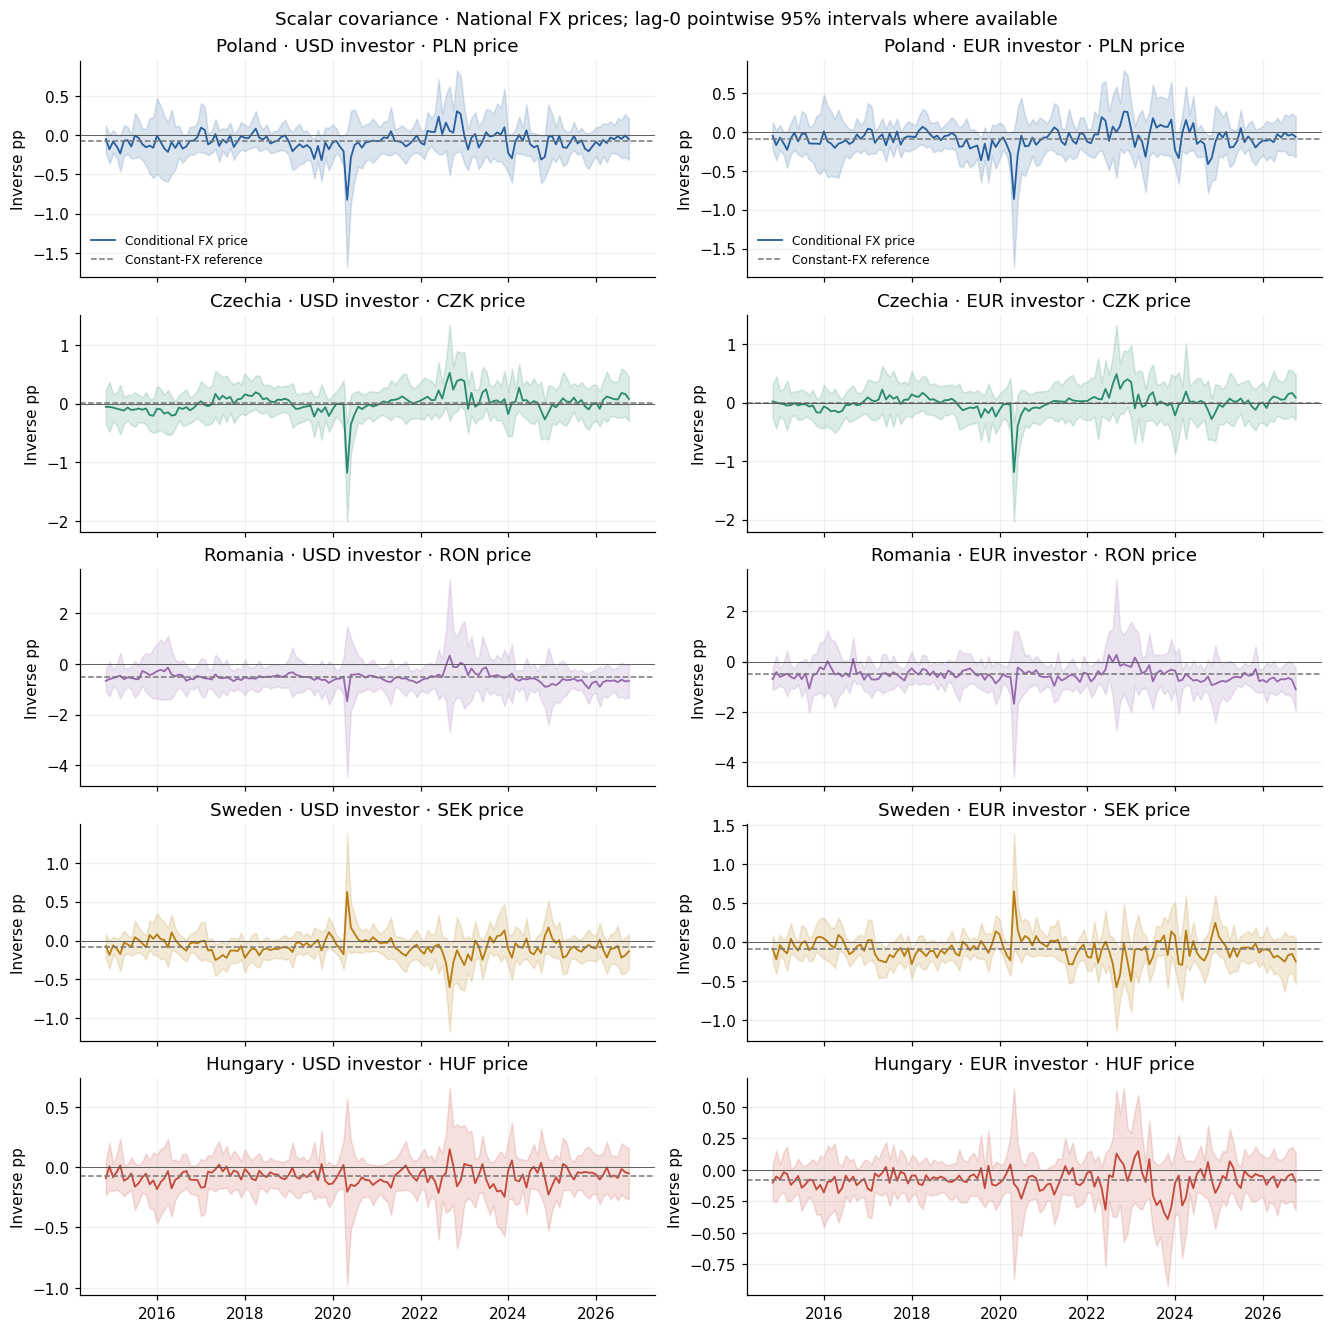

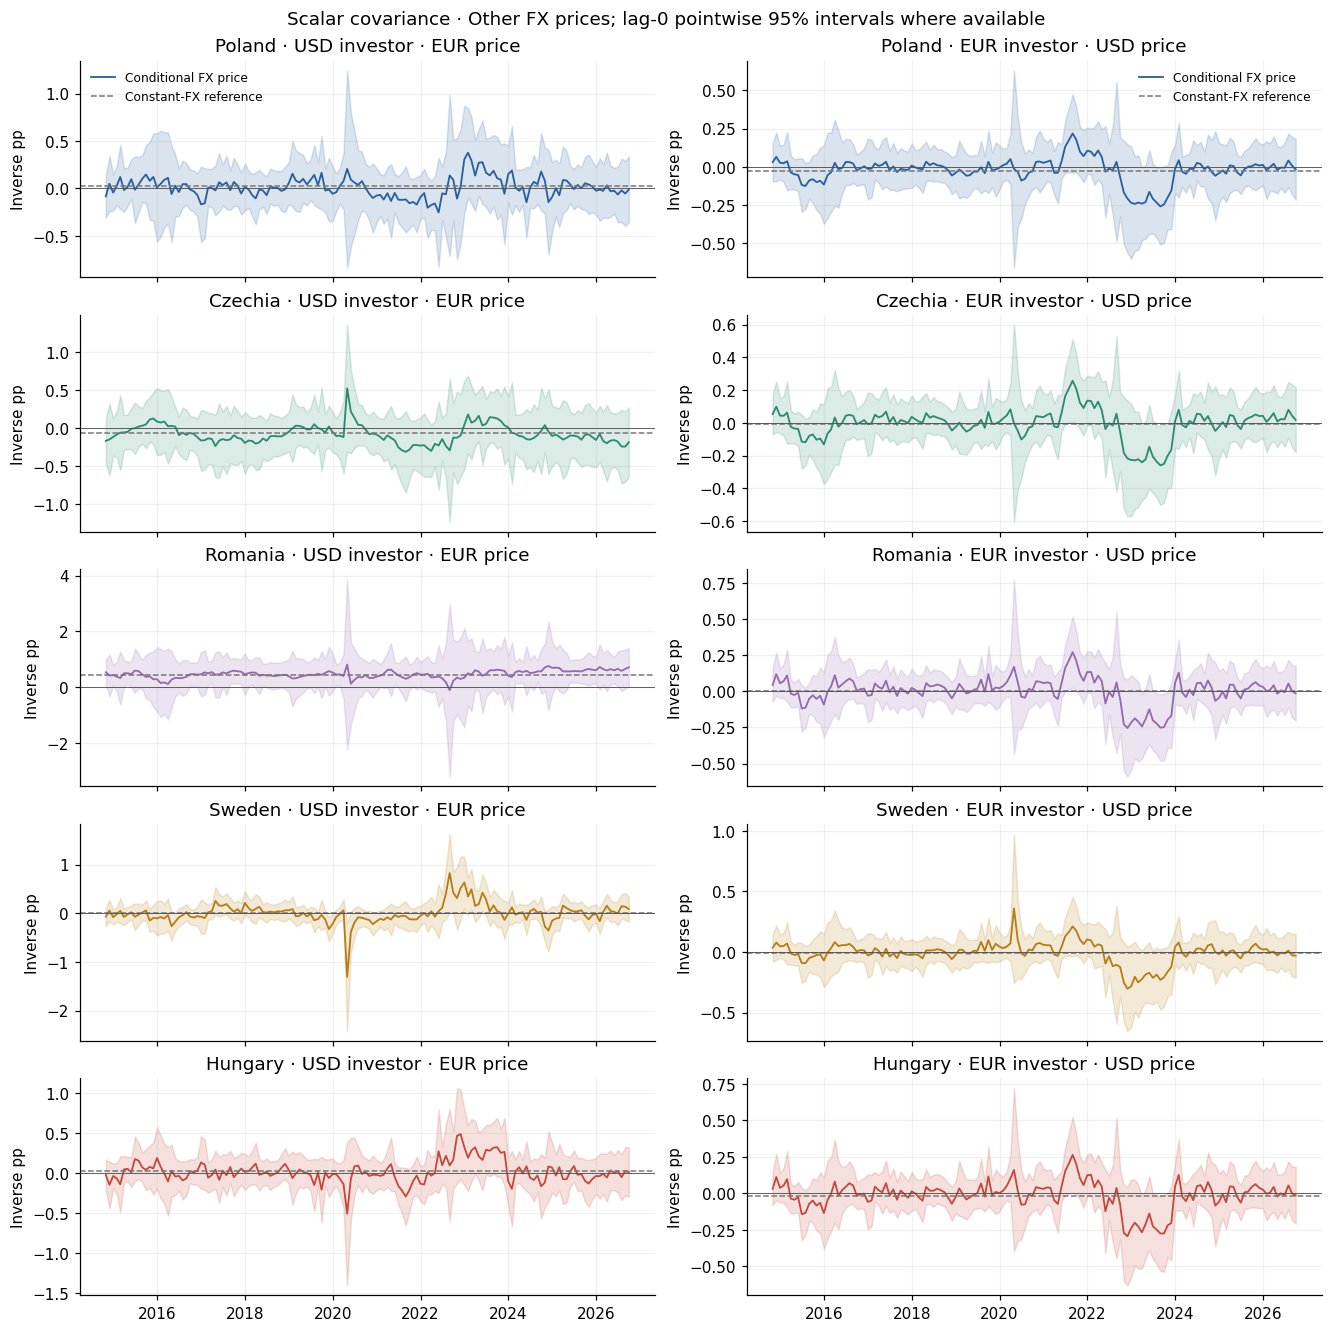

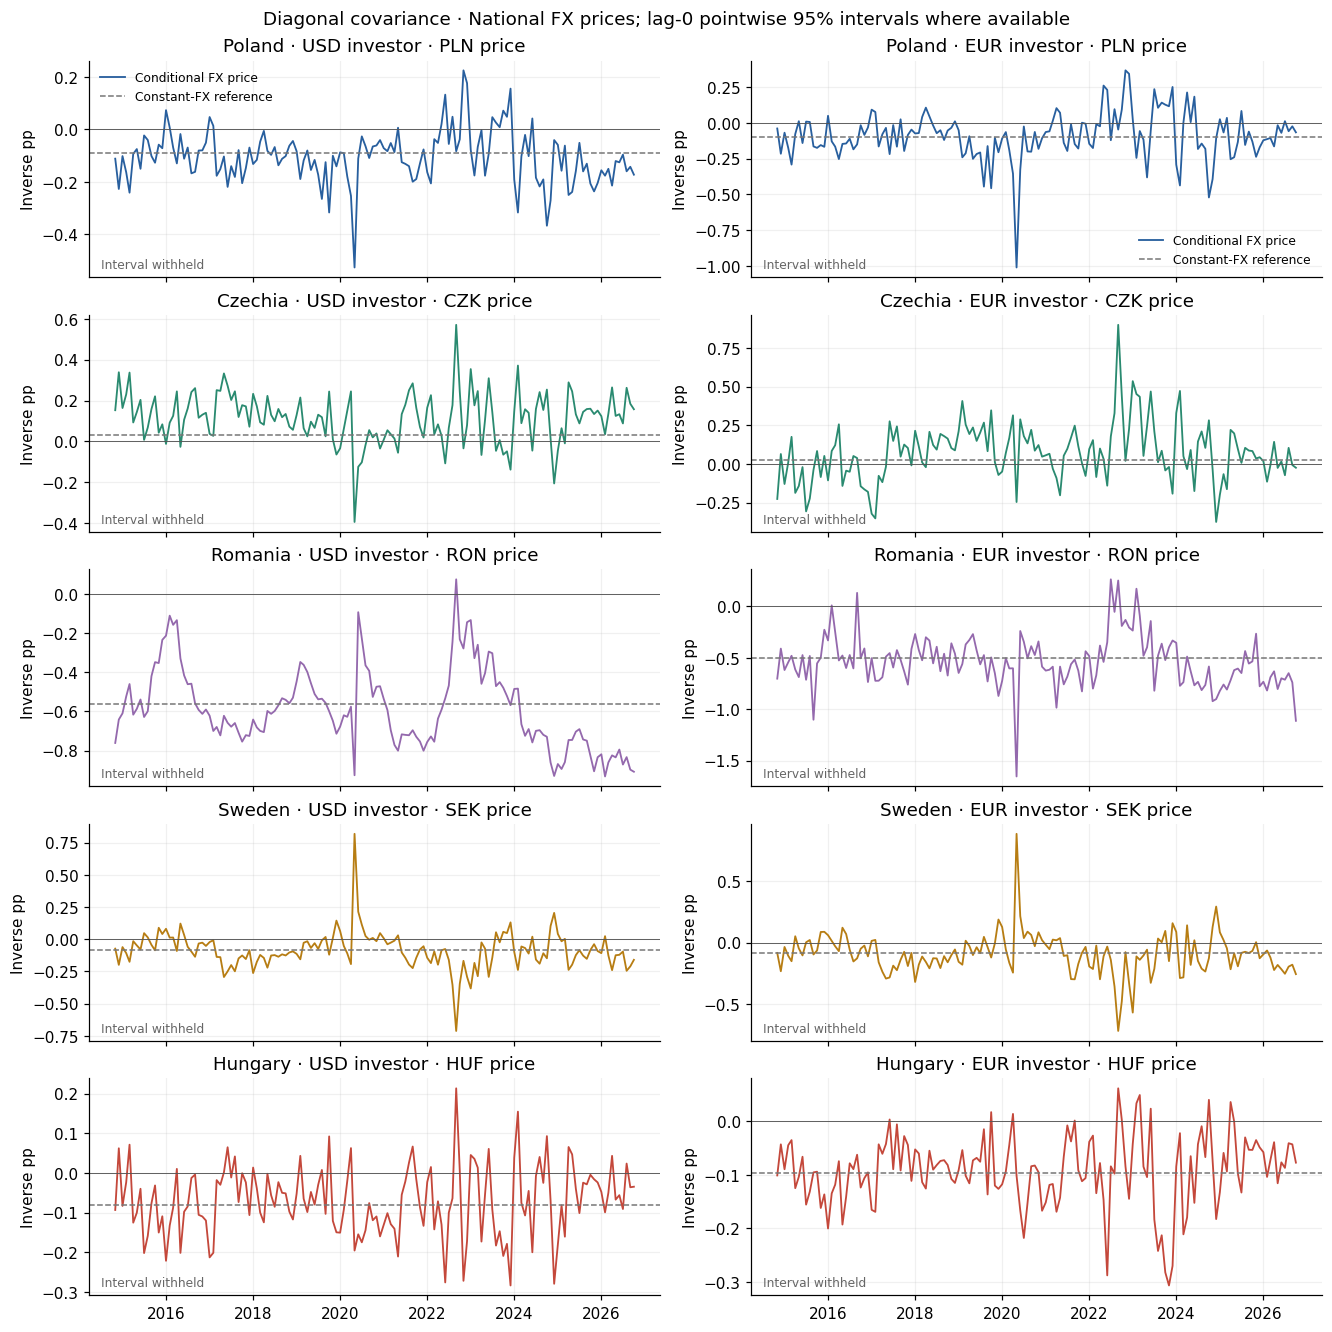

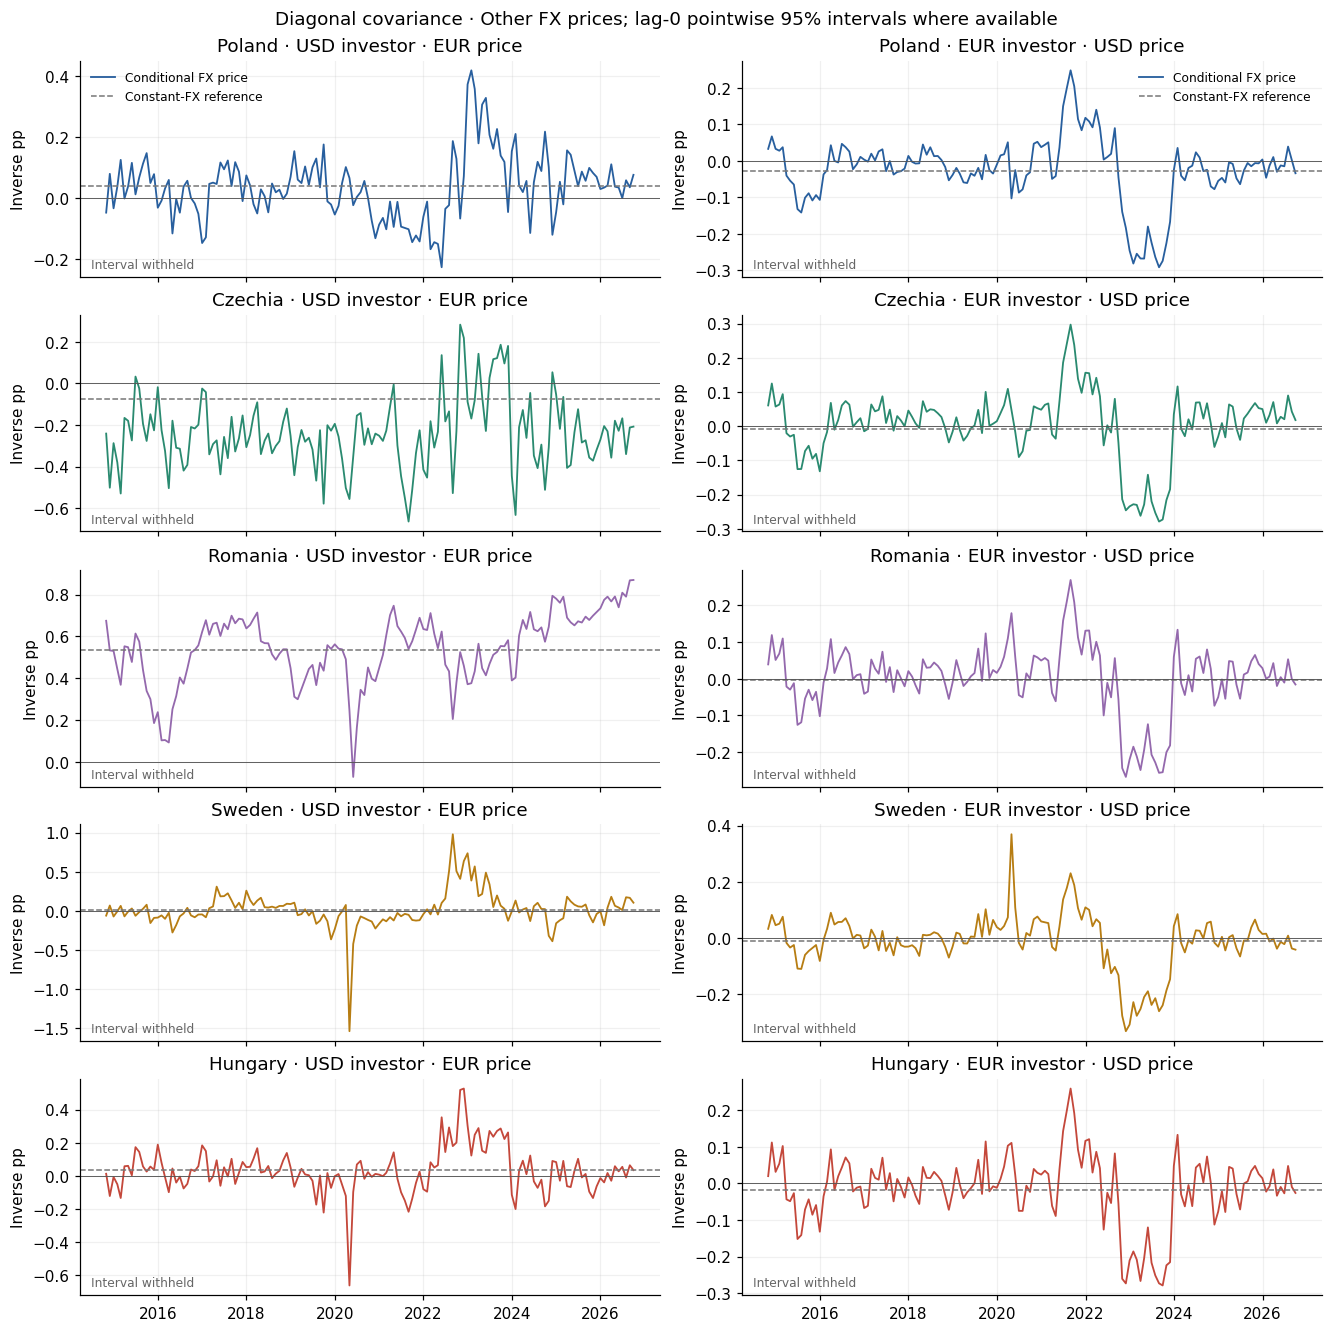

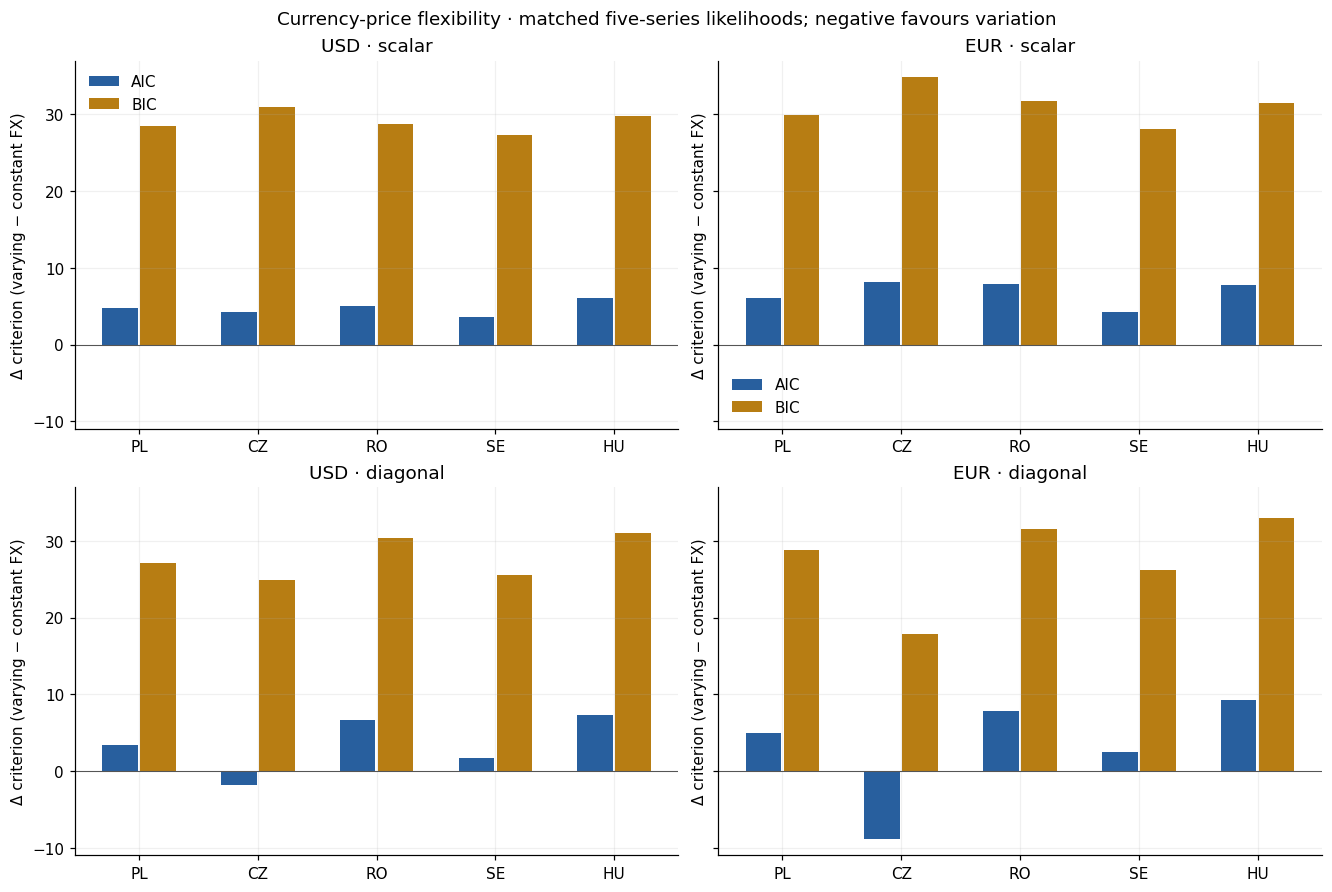

In [8]:
premium_rows, summary_rows, comparison_rows, product_rows = [], [], [], []
for (country, currency, covariance, model), fit in all_fits.items():
    f = fit["filter"]
    prices = {"world": f["world_prices"], "national_FX": f["fx_prices"][:, 0], "other_FX": f["fx_prices"][:, 1], "local": np.full(len(months), f["prices"][2])}
    covs = {"world": f["H"][:, 2, 0], "national_FX": f["H"][:, 2, 3], "other_FX": f["H"][:, 2, 4], "local": f["H"][:, 2, 2]}
    components = {risk: prices[risk]*covs[risk] for risk in prices}
    total = sum(components.values())
    np.testing.assert_allclose(total, f["mu"][:, 2], atol=1e-11, rtol=0)
    for risk, index in [("world", 0), ("national_FX", 3), ("other_FX", 4)]:
        np.testing.assert_allclose(prices[risk].mean(), engine.PRICE_SCALE*fit["theta"][index], atol=1e-12, rtol=0)
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    for risk in prices:
        product_rows.append({**tags, "component": risk, "mean_risk_price": prices[risk].mean(), "mean_covariance_pp2": covs[risk].mean(),
            "mean_contribution_pp": components[risk].mean(), "product_of_means_pp": prices[risk].mean()*covs[risk].mean(),
            "price_covariance_interaction_pp": components[risk].mean()-prices[risk].mean()*covs[risk].mean(),
            "negative_price_pct": 100*np.mean(prices[risk] < 0), "negative_contribution_pct": 100*np.mean(components[risk] < 0)})
    for t, month in enumerate(months):
        premium_rows.append({**tags, "month": str(month), **{name+"_price": v[t] for name, v in prices.items()},
            **{name+"_covariance_pp2": v[t] for name, v in covs.items()}, **{name+"_premium_pp": v[t] for name, v in components.items()},
            "currency_total_pp": components["national_FX"][t]+components["other_FX"][t], "fitted_mean_pp": total[t]})
    if model != "time_varying_fx": continue
    same = fit_table.query("country == @country and perspective == @currency and covariance == @covariance").set_index("model")
    choose = lambda name, lag: tests.loc[(tests.country == country) & (tests.perspective == currency) & (tests.covariance == covariance)
        & (tests.model == model) & (tests.restriction == name) & (tests.HAC_lag == lag), "p_value"].iloc[0]
    r = residuals.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying_fx'")
    c = cross.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying_fx'")
    da = same.loc[model, "AIC"]-same.loc["constant_fx", "AIC"]
    db = same.loc[model, "BIC"]-same.loc["constant_fx", "BIC"]
    comparison_rows.append({**tags, "delta_AIC": da, "delta_BIC": db, "loglik_gain": same.loc[model, "loglik"]-same.loc["constant_fx", "loglik"],
        "added_parameters": int(same.loc[model, "parameters"]-same.loc["constant_fx", "parameters"])})
    summary_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "covariance": covariance, "months": len(months),
        "FX_constancy_p_QML": choose("Both FX prices constant", 0), "FX_constancy_p_HAC12": choose("Both FX prices constant", 12),
        "national_FX_constancy_p_QML": choose("National FX price constant", 0), "other_FX_constancy_p_QML": choose("Other FX price constant", 0),
        "FX_joint_zero_p_QML": choose("FX prices jointly zero", 0), "delta_AIC": da, "delta_BIC": db,
        "mean_national_FX_price": prices["national_FX"].mean(), "national_FX_negative_price_pct": 100*np.mean(prices["national_FX"] < 0),
        "mean_other_FX_price": prices["other_FX"].mean(), "other_FX_negative_price_pct": 100*np.mean(prices["other_FX"] < 0),
        **{"mean_"+risk+"_premium_pp": v.mean() for risk, v in components.items()},
        "mean_currency_total_pp": (components["national_FX"]+components["other_FX"]).mean(),
        "numerical_inference_ready": fit["inference"]["estimates"][0]["ready"], "inference_reason": fit["inference"]["estimates"][0]["reason"],
        "mean_flags_holm_5pct": int(r.LB_z_p_holm.lt(.05).sum()),
        "variance_flags_holm_5pct": int((r.LB_z_squared_p_holm.lt(.05) | r.ARCH_LM_p_holm.lt(.05)).sum()),
        "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
premiums, summary, comparison, product_summary = map(pd.DataFrame, [premium_rows, summary_rows, comparison_rows, product_rows])
for covariance in COVARIANCES:
    for risk, index in [("National FX", 3), ("Other FX", 4)]:
        fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
        for row, country in enumerate(NAMES):
            for col, currency in enumerate(CURRENCIES):
                ax = axes[row, col]
                p = price_paths.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying_fx' and risk == @risk and HAC_lag == 0")
                dates = months.to_timestamp("M")
                ax.plot(dates, p.risk_price, color=COLORS[country], lw=1.2, label="Conditional FX price")
                ax.axhline(constant_fits[(country, currency, covariance)]["filter"]["prices"][index], color="#777777", ls="--", lw=1, label="Constant-FX reference")
                if p.inference_ready.all(): ax.fill_between(dates, p.ci95_low, p.ci95_high, color=COLORS[country], alpha=.17)
                else: ax.text(.02, .04, "Interval withheld", transform=ax.transAxes, color="#666666", fontsize=8)
                ax.axhline(0, color="#555555", lw=.6)
                fx = LOCAL_CURRENCIES[country] if index == 3 else ("EUR" if currency == "USD" else "USD")
                ax.set(title=f"{NAMES[country]} · {currency} investor · {fx} price", ylabel="Inverse pp")
                if row == 0: ax.legend(frameon=False, fontsize=8)
        fig.suptitle(f"{covariance.capitalize()} covariance · {risk} prices; lag-0 pointwise 95% intervals where available")
        save_plot(f"02_{risk.replace(' ', '_')}_prices_{covariance}.png")
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, layout="constrained")
for row, covariance in enumerate(COVARIANCES):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        p = comparison.query("perspective == @currency and covariance == @covariance").set_index("country").loc[list(NAMES)]
        x = np.arange(5)
        ax.bar(x-.16, p.delta_AIC, width=.3, color="#285f9e", label="AIC")
        ax.bar(x+.16, p.delta_BIC, width=.3, color="#b77d13", label="BIC")
        ax.axhline(0, color="#555555", lw=.7)
        ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} · {covariance}", ylabel="Δ criterion (varying − constant FX)")
        if row == 0: ax.legend(frameon=False)
fig.suptitle("Currency-price flexibility · matched five-series likelihoods; negative favours variation")
save_plot("03_model_comparison.png")

## 8. Final comparison and reproducibility

Compare each country with Hungary on the same dates. Keep pricing significance, numerical
readiness and residual adequacy separate. A missing interval/test remains unavailable; a smooth
path is not evidence of a stable conditional risk price. Persistent other-FX gap levels, the carried
US inflation observation, crisis leverage and the short window remain targeted robustness items.

The next modelling extension is time-varying national local prices, followed by aligned final-model
comparisons and regional robustness checks. A hedged-versus-unhedged analysis needs explicit
hedged returns, forward/carry costs and comparable investable exposures; this notebook does not
identify a causal currency burden.

In [9]:
display(summary.set_index(["name", "perspective", "covariance"])[["FX_constancy_p_QML", "FX_constancy_p_HAC12", "delta_AIC", "delta_BIC",
    "mean_national_FX_price", "mean_national_FX_premium_pp", "mean_other_FX_premium_pp", "numerical_inference_ready"]].round(5))
display(summary.set_index(["name", "perspective", "covariance"])[["inference_reason", "mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])
tables = {"input_audit.csv": input_audit, "inflation_instrument_audit.csv": audit, "regime_audit.csv": regimes,
    "design_audit.csv": design_audit, "instrument_transform.csv": transform_table, "conditioning_design.csv": conditioning,
    "instrument_VIF.csv": vifs, "instrument_leverage.csv": leverages, "inflation_candidates.csv": candidates, "inflation_quality_flags.csv": quality_flags,
    "implementation_checks.csv": checks, "starting_points.csv": starts_table, "fit_summary.csv": fit_table,
    "price_coefficients.csv": coefficients, "restriction_tests.csv": tests, "inference_audit.csv": inference_audit,
    "parameter_bounds.csv": boundary_audit, "risk_price_paths.csv": price_paths, "residual_diagnostics.csv": residuals,
    "cross_covariance_diagnostics.csv": cross, "premium_components.csv": premiums, "price_covariance_products.csv": product_summary,
    "model_comparison.csv": comparison, "common_comparison.csv": summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator="\n")
parameter_files = []
for (country, currency, covariance, model), fit in all_fits.items():
    name = f"parameters_{country}_{currency}_{covariance}_{model}.npz"
    f = fit["filter"]
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"], target=f["target"], intercept=f["intercept"],
        Hessian=fit["inference"]["Hessian"], **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes and engine_hashes == {name: sha((ROOT/name).read_bytes()) for name in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files]+[f"fit_{c}_{p}_{v}_time_varying_fx.json" for c, p, v in fits]
metadata = {"notebook": "25_regional_time_varying_currency.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months),
    "estimated_fits": len(fits), "constant_FX_reference_fits": len(constant_fits), "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "spec": spec, "designs": design_audit.to_dict("records"), "normalizers": transform_table.to_dict("records"),
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Frozen common 144 months; national/other FX prices linear in audited predetermined conditioners",
        "World design identical to notebook 24; world/local/covariance parameters jointly re-estimated; local prices constant",
        "Corrected five priced means; zero alphas; scalar and diagonal covariance retained",
        "Raw inflation reconstruction before sample trim; inherited annual-US-inflation carry explicitly flagged; no market-data filling",
        "Only varying regime columns included; all tests/intervals suppressed on numerical failures",
        "Fixed QML/HAC 0/3/6/12; pointwise price intervals; exploratory pricing tests unadjusted",
        "Premium means are means of monthly price-covariance products, not products of means"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+"\n")

primary = tests.query("model == 'time_varying_fx' and restriction == 'Both FX prices constant'")
count_tests = lambda lag: f"{int(primary.loc[primary.HAC_lag.eq(lag), 'p_value'].lt(.05).sum())}/{int(primary.loc[primary.HAC_lag.eq(lag), 'p_value'].notna().sum())}"
ready_counts = summary.groupby("covariance").numerical_inference_ready.agg(["sum", "size"])
readiness = "; ".join(f"{cov}: {int(row['sum'])}/{int(row['size'])}" for cov, row in ready_counts.iterrows())
display(Markdown(f"**Reading this run:** AIC favours time-varying FX prices in **{int(summary.delta_AIC.lt(0).sum())}/20** systems; "
    f"BIC favours constant FX prices in **{int(summary.delta_BIC.gt(0).sum())}/20**. "
    f"The joint FX-constancy test rejects at an unadjusted 5% level in **{count_tests(0)}** available lag-0 tests and "
    f"**{count_tests(12)}** available lag-12 tests. This bandwidth sensitivity needs robustness work before a general pricing claim.\n\n"
    f"**Primary inference available:** {readiness}. Unavailable tests/intervals remain withheld; inspect the recorded numerical reasons. "
    "Compare these pricing tests separately from model-selection criteria and residual adequacy."))

unready = int((~summary.numerical_inference_ready).sum())
display(Markdown(f"**Completed:** {len(fits)} conditional-FX fits against {len(constant_fits)} verified constant-FX references, "
    f"all on **{months[0]}–{months[-1]} ({len(months)} months)** in base. **{unready}/20** new systems have suppressed primary inference. "
    f"Saved {len(tables)} tables and {len(figure_files)} charts in `{OUT.relative_to(ROOT)}`. All frozen data and prior outputs remain unchanged."))

FX_constancy_p_QML  FX_constancy_p_HAC12  \
name    perspective covariance                                             
Hungary USD         scalar                 0.31314               0.00113   
                    diagonal                   NaN                   NaN   
        EUR         scalar                 0.53690               0.02825   
                    diagonal                   NaN                   NaN   
Poland  USD         scalar                 0.23183               0.00000   
                    diagonal                   NaN                   NaN   
        EUR         scalar                 0.31803               0.00002   
                    diagonal                   NaN                   NaN   
Czechia USD         scalar                 0.03831               0.00001   
                    diagonal                   NaN                   NaN   
        EUR         scalar                 0.03146               0.00000   
                    diagonal                   NaN                   NaN   
Romania USD         scalar                 0.22130               0.00110   
                    diagonal                   NaN                   NaN   
        EUR         scalar                 0.36378               0.01013   
                    diagonal                   NaN                   NaN   
Sweden  USD         scalar                 0.18384               0.00002   
                    diagonal                   NaN                   NaN   
        EUR         scalar                 0.13636               0.00000   
                    diagonal                   NaN                   NaN   

                                delta_AIC  delta_BIC  mean_national_FX_price  \
name    perspective covariance                                                 
Hungary USD         scalar        6.01808   29.77658                -0.07654   
                    diagonal      7.30494   31.06344                -0.06987   
        EUR         scalar        7.76827   31.52677                -0.08284   
                    diagonal      9.27683   33.03534                -0.09165   
Poland  USD         scalar        4.79747   28.55598                -0.07847   
                    diagonal      3.42401   27.18251                -0.10615   
        EUR         scalar        6.13139   29.88990                -0.08984   
                    diagonal      5.00288   28.76139                -0.09185   
Czechia USD         scalar        4.25425   30.98257                 0.00511   
                    diagonal     -1.78202   24.94630                 0.11565   
        EUR         scalar        8.12760   34.85592                -0.00532   
                    diagonal     -8.80681   17.92151                 0.07162   
Romania USD         scalar        5.04054   28.79905                -0.53557   
                    diagonal      6.58626   30.34476                -0.58743   
        EUR         scalar        7.95248   31.71099                -0.53469   
                    diagonal      7.84017   31.59868                -0.53672   
Sweden  USD         scalar        3.54517   27.30367                -0.07919   
                    diagonal      1.76143   25.51993                -0.08597   
        EUR         scalar        4.31052   28.06903                -0.08544   
                    diagonal      2.41736   26.17587                -0.09036   

                                mean_national_FX_premium_pp  \
name    perspective covariance                                
Hungary USD         scalar                         -1.11293   
                    diagonal                       -1.02396   
        EUR         scalar                         -0.55791   
                    diagonal                       -0.63204   
Poland  USD         scalar                         -1.28152   
                    diagonal                       -1.77496   
        EUR         scalar                         -0.56185   
                    diagonal   

inference_reason  \
name    perspective covariance                                                      
Hungary USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Poland  USD         scalar                                      numerically ready   
                    diagonal    parameter bound; nonpositive curvature; ill-co...   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Czechia USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Romania USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal     nonpositive curvature; ill-conditioned curvature   
Sweden  USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   

                                mean_flags_holm_5pct  \
name    perspective covariance                         
Hungary USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Poland  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Czechia USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Romania USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Sweden  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   

                                variance_flags_holm_5pct  \
name    perspective covariance                             
Hungary USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Poland  USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             1   
                    diagonal                           0   
Czechia USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Romania USD         scalar                             0   
                    diagonal                           0   
 

**Reading this run:** AIC favours time-varying FX prices in **2/20** systems; BIC favours constant FX prices in **20/20**. The joint FX-constancy test rejects at an unadjusted 5% level in **2/10** available lag-0 tests and **10/10** available lag-12 tests. This bandwidth sensitivity needs robustness work before a general pricing claim.

**Primary inference available:** diagonal: 0/10; scalar: 10/10. Unavailable tests/intervals remain withheld; inspect the recorded numerical reasons. Compare these pricing tests separately from model-selection criteria and residual adequacy.

**Completed:** 20 conditional-FX fits against 20 verified constant-FX references, all on **2014-10–2026-09 (144 months)** in base. **10/20** new systems have suppressed primary inference. Saved 24 tables and 6 charts in `output/25_regional_time_varying_currency/2014-10_2026-09/fx_a9208202`. All frozen data and prior outputs remain unchanged.